## Project 3 Data Analysis Using Python Lukas Kvilitaia


### My project's objective is to find out a couple of things about the games. But only the games themselves,
### so i will not talk about or analyse any expansions/DLC's
##### My goals are:
##### 1) To find out if the games price affects reviews.
##### 2) To find out what genre of games are the most played.
##### 3) To find out if the prices of games went up.
##### 4) To find out what is the most popular month for publishing games.
##### And some extra stuff that i think is important.

In [1]:
# importing some libraries that i might use
import pandas as pd
import seaborn as sb
import datetime as dt
import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
# getting the dataframe
df = pd.read_csv('steam_games/SteamGames.csv')

In [3]:
# lets take a look at it
df.columns

Index(['Appid', 'Name', 'Type', 'ReleaseDate', 'Genres', 'Developers',
       'Publishers', 'price', 'Thumbnail', 'Tags', 'ReviewScore',
       'PositiveReview', 'NegativeReview', 'Rank'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29676 entries, 0 to 29675
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Appid           29676 non-null  int64  
 1   Name            29676 non-null  str    
 2   Type            29676 non-null  str    
 3   ReleaseDate     29672 non-null  str    
 4   Genres          29676 non-null  str    
 5   Developers      29676 non-null  str    
 6   Publishers      29676 non-null  str    
 7   price           29676 non-null  float64
 8   Thumbnail       29676 non-null  str    
 9   Tags            29676 non-null  str    
 10  ReviewScore     29676 non-null  int64  
 11  PositiveReview  29676 non-null  int64  
 12  NegativeReview  29676 non-null  int64  
 13  Rank            29676 non-null  int64  
dtypes: float64(1), int64(5), str(8)
memory usage: 3.2 MB


In [5]:
df.head()

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,Rank
0,3764200,Resident Evil Requiem,game,2026-02-26,"Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",69.99,https://shared.akamai.steamstatic.com/store_it...,"Action,Adventure",9,23715,793,1
1,730,Counter-Strike 2,game,2012-08-21,"Action,Free To Play",Valve,Valve,0.00,https://shared.akamai.steamstatic.com/store_it...,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393,2
2,1808500,ARC Raiders,game,2025-10-30,Action,Embark Studios,Embark Studios,39.99,https://shared.akamai.steamstatic.com/store_it...,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194,3
3,359550,Tom Clancy's Rainbow Six Siege,game,2015-12-01,"Action,Free To Play",Ubisoft Montreal,Ubisoft,0.00,https://shared.akamai.steamstatic.com/store_it...,"Action,Free To Play",8,522886,106839,4
4,1172470,Apex Legends™,game,2020-11-04,"Action,Adventure,Free To Play",Respawn,Electronic Arts,0.00,https://shared.akamai.steamstatic.com/store_it...,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216,5


In [8]:
# fixing some of the data
df.ReleaseDate = pd.to_datetime(df.ReleaseDate, format='mixed')
df.price = df.price.replace('$','').astype(float)

In [9]:
df.head()

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,Rank
0,3764200,Resident Evil Requiem,game,2026-02-26,"Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",69.99,https://shared.akamai.steamstatic.com/store_it...,"Action,Adventure",9,23715,793,1
1,730,Counter-Strike 2,game,2012-08-21,"Action,Free To Play",Valve,Valve,0.00,https://shared.akamai.steamstatic.com/store_it...,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393,2
2,1808500,ARC Raiders,game,2025-10-30,Action,Embark Studios,Embark Studios,39.99,https://shared.akamai.steamstatic.com/store_it...,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194,3
3,359550,Tom Clancy's Rainbow Six Siege,game,2015-12-01,"Action,Free To Play",Ubisoft Montreal,Ubisoft,0.00,https://shared.akamai.steamstatic.com/store_it...,"Action,Free To Play",8,522886,106839,4
4,1172470,Apex Legends™,game,2020-11-04,"Action,Adventure,Free To Play",Respawn,Electronic Arts,0.00,https://shared.akamai.steamstatic.com/store_it...,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216,5


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29676 entries, 0 to 29675
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Appid           29676 non-null  int64         
 1   Name            29676 non-null  str           
 2   Type            29676 non-null  str           
 3   ReleaseDate     29672 non-null  datetime64[us]
 4   Genres          29676 non-null  str           
 5   Developers      29676 non-null  str           
 6   Publishers      29676 non-null  str           
 7   price           29676 non-null  float64       
 8   Thumbnail       29676 non-null  str           
 9   Tags            29676 non-null  str           
 10  ReviewScore     29676 non-null  int64         
 11  PositiveReview  29676 non-null  int64         
 12  NegativeReview  29676 non-null  int64         
 13  Rank            29676 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(5), str(7)
memory usage: 

#### Some things that you should know about the data

In [11]:
# Type = type of game (game,DLC,soundtrack,etc)
# Genres = all the main genres of the game
# Tags = All the genres of the game
# Rank = popularity at the time the data was taken

# All the other ones are pretty self explanatory

##### fixing nulls

In [12]:
df.isna().sum()

Appid             0
Name              0
Type              0
ReleaseDate       4
Genres            0
Developers        0
Publishers        0
price             0
Thumbnail         0
Tags              0
ReviewScore       0
PositiveReview    0
NegativeReview    0
Rank              0
dtype: int64

In [13]:
# lets see all the release dates that are null
df[df['ReleaseDate'].isna()]

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,Rank
16513,249860,Arma 3 Soundtrack,music,NaT,"Action,Simulation,Strategy",Bohemia Interactive,Bohemia Interactive,9.99,https://shared.akamai.steamstatic.com/store_it...,"Action,Simulation,Strategy",7,21,1,3396
20303,57925,Duke Nukem Forever: The Doctor Who Cloned Me,dlc,NaT,Action,Gearbox Software,2K,9.99,https://shared.akamai.steamstatic.com/store_it...,Action,6,23,6,7224
20807,409552,Divinity: Original Sin Enhanced Edition - Offi...,music,NaT,"Adventure,Indie,RPG,Strategy",Larian Studios,Larian Studios,4.99,https://shared.akamai.steamstatic.com/store_it...,"RPG,Strategy,Indie,Adventure,Soundtrack",5,8,4,7739
24013,257020,Guacamelee! Soundtrack,music,NaT,Soundtrack,Drinkbox Studios,"Drinkbox Studios,Kepler Ghost",3.49,https://shared.akamai.steamstatic.com/store_it...,"Soundtrack,Action,Adventure,Indie",0,3,1,10994


In [14]:
# there aren't too many of them so lets fix them one by one by looking up their release dates on Google

In [15]:
mask = df.Appid == 242050
df.loc[mask,'ReleaseDate'] = "2013-11-19"

In [16]:
mask = df.Appid == 223850
df.loc[mask,'ReleaseDate'] = "2013-2-04"

In [17]:
mask = df.Appid == 564310
df.loc[mask,'ReleaseDate'] = "2017-3-20"

In [18]:
mask = df.Appid == 202170
df.loc[mask,'ReleaseDate'] = "2014-10-08"

In [19]:
mask = df.Appid == 63380
df.loc[mask,'ReleaseDate'] = "2014-6-05"

In [20]:
mask = df.Appid == 11180
df.loc[mask,'ReleaseDate'] = "2008-5-09"

In [21]:
mask = df.Appid == 233370
df.loc[mask,'ReleaseDate'] = "2013-7-23"

In [22]:
mask = df.Appid == 38480
df.loc[mask,'ReleaseDate'] = "2009-11-04"

In [23]:
mask = df.Appid == 214560
df.loc[mask,'ReleaseDate'] = "2012-10-16"

In [24]:
# i didn't give all of them a date because some of them were not games

In [25]:
df[df['ReleaseDate'].isna()]

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,Rank
16513,249860,Arma 3 Soundtrack,music,NaT,"Action,Simulation,Strategy",Bohemia Interactive,Bohemia Interactive,9.99,https://shared.akamai.steamstatic.com/store_it...,"Action,Simulation,Strategy",7,21,1,3396
20303,57925,Duke Nukem Forever: The Doctor Who Cloned Me,dlc,NaT,Action,Gearbox Software,2K,9.99,https://shared.akamai.steamstatic.com/store_it...,Action,6,23,6,7224
20807,409552,Divinity: Original Sin Enhanced Edition - Offi...,music,NaT,"Adventure,Indie,RPG,Strategy",Larian Studios,Larian Studios,4.99,https://shared.akamai.steamstatic.com/store_it...,"RPG,Strategy,Indie,Adventure,Soundtrack",5,8,4,7739
24013,257020,Guacamelee! Soundtrack,music,NaT,Soundtrack,Drinkbox Studios,"Drinkbox Studios,Kepler Ghost",3.49,https://shared.akamai.steamstatic.com/store_it...,"Soundtrack,Action,Adventure,Indie",0,3,1,10994


In [26]:
# new lets get rid of all the games that don't have a developer (because how can you make a game without a dev)
# however lets keep the ones that don't have a publisher because there are a lot of independent devs that don't use publishers
# but we should still fix the nulls by replacing them with thier developer's name

In [27]:
df = df.dropna(axis=0,subset='Developers')

In [28]:
mask = df.Publishers.isna()
df.loc[mask,'Publishers'] = df.loc[mask,'Developers']

In [29]:
# now for genres and tags, for games that don't have a genre but have tags, we can just give them the first tag as thier genre
# but tags are more of an extra they aren't really nessesery but we can just give games without tags thier genre
# the only problem are games that have no tags and no genre we can't really do anything about those so we will just get rid of them

In [30]:
df.query('Genres.isna() and Tags.isna()').head()

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,Rank


In [31]:
# remove all the ones with nulls in both
df.dropna(axis=0,subset=['Genres','Tags'],how='all',inplace=True)

In [32]:
# if the genre is null fill it with the first tag
mask = df.Genres.isna()
df.loc[mask,'Genres'] = df.loc[mask,'Tags'].str.split(',').str[0]

In [33]:
# if the tags are empty fill them with the genres
mask = df.Tags.isna()
df.loc[mask,'Tags'] = df.loc[mask,'Genres']

In [34]:
df.isna().sum()

Appid             0
Name              0
Type              0
ReleaseDate       4
Genres            0
Developers        0
Publishers        0
price             0
Thumbnail         0
Tags              0
ReviewScore       0
PositiveReview    0
NegativeReview    0
Rank              0
dtype: int64

In [35]:
# now for the pc requirments i CAN just fill them up with the most common requirments but that would be very wrong
# because some pc's will not be able to run very big games and the most common requirments for games are really not that crazy
# but i will not delete them from the dataframe i will just keep them blank

In [36]:
# lets make a new dataframe that actually has information that can be usefull and only get back games
mask = df.Type == 'game'
new_df = df[['Appid','Name','ReleaseDate','Genres','Developers','Publishers','price','Tags','ReviewScore',
             'PositiveReview','NegativeReview',]][mask]

In [37]:
new_df.head()

,Appid,Name,ReleaseDate,Genres,Developers,Publishers,price,Tags,ReviewScore,PositiveReview,NegativeReview
0,3764200,Resident Evil Requiem,2026-02-26,"Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",69.99,"Action,Adventure",9,23715,793
1,730,Counter-Strike 2,2012-08-21,"Action,Free To Play",Valve,Valve,0.00,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393
2,1808500,ARC Raiders,2025-10-30,Action,Embark Studios,Embark Studios,39.99,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194
3,359550,Tom Clancy's Rainbow Six Siege,2015-12-01,"Action,Free To Play",Ubisoft Montreal,Ubisoft,0.00,"Action,Free To Play",8,522886,106839
4,1172470,Apex Legends™,2020-11-04,"Action,Adventure,Free To Play",Respawn,Electronic Arts,0.00,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216


In [38]:
new_df.info()

<class 'pandas.DataFrame'>
Index: 22694 entries, 0 to 29675
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Appid           22694 non-null  int64         
 1   Name            22694 non-null  str           
 2   ReleaseDate     22694 non-null  datetime64[us]
 3   Genres          22694 non-null  str           
 4   Developers      22694 non-null  str           
 5   Publishers      22694 non-null  str           
 6   price           22694 non-null  float64       
 7   Tags            22694 non-null  str           
 8   ReviewScore     22694 non-null  int64         
 9   PositiveReview  22694 non-null  int64         
 10  NegativeReview  22694 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(5)
memory usage: 2.1 MB


In [39]:
# extra info

In [40]:
new_df.describe()

,Appid,ReleaseDate,price,ReviewScore,PositiveReview,NegativeReview
count,2.269400e+04,22694,22694.000000,22694.000000,2.269400e+04,22694.000000
mean,1.688171e+06,2021-06-26 22:22:47.409888,12.620672,6.846611,2.059570e+03,291.944038
min,1.000000e+01,1997-06-30 00:00:00,0.000000,0.000000,0.000000e+00,0.000000
25%,7.105025e+05,2018-10-16 00:00:00,4.990000,6.000000,3.400000e+01,4.000000
50%,1.533635e+06,2022-09-09 00:00:00,9.990000,8.000000,1.100000e+02,16.000000
75%,2.532902e+06,2024-11-26 00:00:00,17.990000,8.000000,5.020000e+02,81.000000
max,4.426850e+06,2026-08-27 00:00:00,269.990000,9.000000,1.214897e+06,202393.000000
std,1.109894e+06,NaN,12.307002,1.986792,1.601776e+04,2607.022385


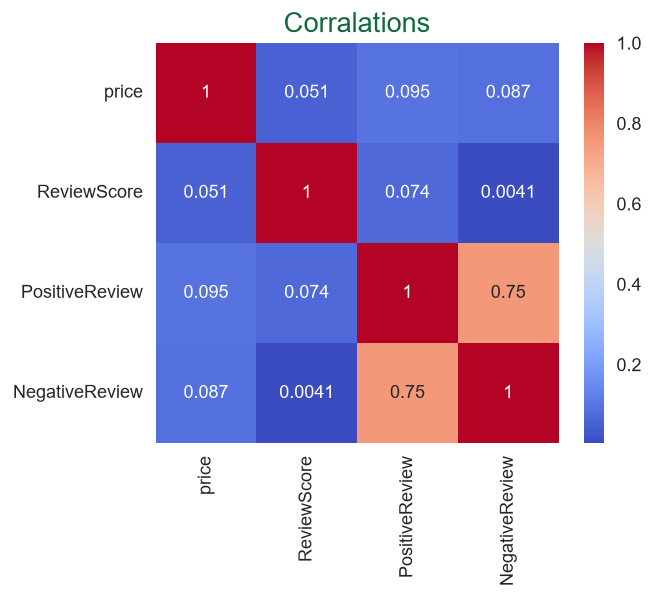

In [41]:
plt.style.use('seaborn-v0_8')

plt.figure(figsize=(5,4),dpi=130)
plt.title('Corralations',fontsize=15,color="#116838")
sb.heatmap(new_df[['price','ReviewScore','PositiveReview','NegativeReview']].corr(),annot=True,cmap='coolwarm',color='#112e1e')
plt.show()

In [42]:
# looking at the correlations we can see is that positive and negative reviews are close
# this tells us that most games get both positive and negative reviews

In [43]:
# now i want to check what percentage of reviews are negative

In [44]:
new_df.PositiveReview.mean()

np.float64(2059.569710055521)

In [45]:
new_df.NegativeReview.mean()

np.float64(291.944038071737)

In [46]:
new_df.NegativeReview.mean()/new_df.PositiveReview.mean()*100

np.float64(14.1750015377662)

In [47]:
# on average 14.17% of reviews are negative

#### lets check if the reviews change if we look at specific groups

In [48]:
# i want to check if the price affects the reviews

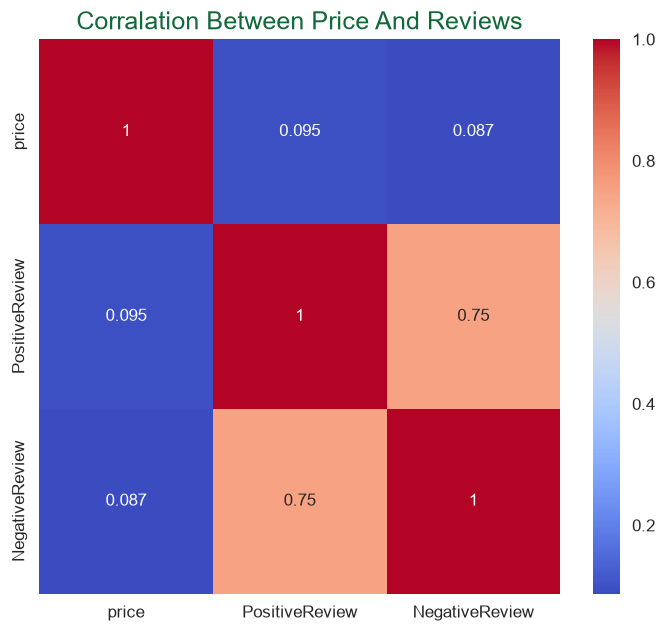

In [49]:
plt.figure(figsize=(7,6),dpi=120)

plt.title('Corralation Between Price And Reviews',fontsize=15,color="#116838")
sb.heatmap(new_df[['price','PositiveReview','NegativeReview']].corr(),annot=True,cmap='coolwarm',color='#112e1e')
plt.show()

In [50]:
# it looks like price doesn't affect the reviews (the redder the color the bigger the corralation)

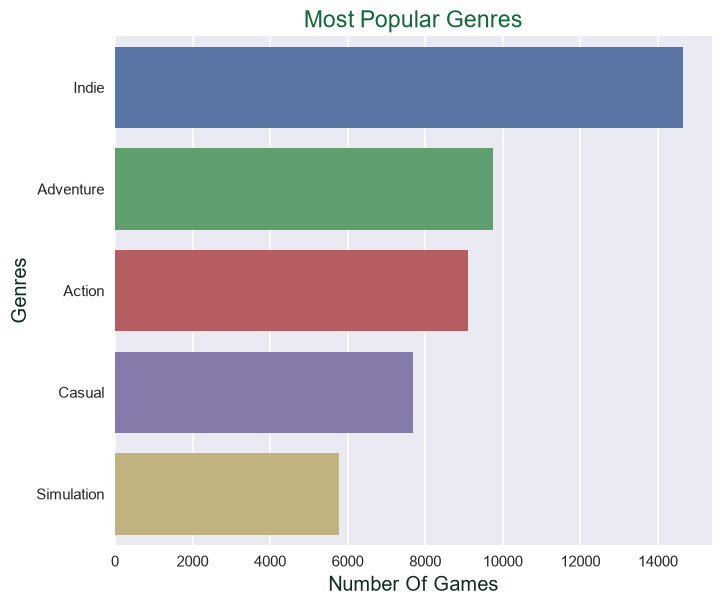

In [51]:
top_genres = new_df.Genres.str.split(',').explode().value_counts().head()

plt.figure(figsize=(7,6),dpi=110)

sb.barplot(y= top_genres.index,x= top_genres.values,hue= top_genres.index)
plt.title('Most Popular Genres',fontsize=15,color="#116838")
plt.xlabel('Number Of Games',fontsize=13,color='#112e1e')
plt.ylabel('Genres',fontsize=13,color='#112e1e')
plt.show()

In [52]:
# the top genre is 'Indie' this makes sense because indie games are usually small so they take less time to make

In [53]:
mask = new_df.Genres == 'Indie'
new_df.loc[mask,['price','PositiveReview','NegativeReview']].mean()

price               7.192236
PositiveReview    768.562500
NegativeReview     58.468750
dtype: float64

In [54]:
new_df[mask].NegativeReview.mean()/new_df[mask].PositiveReview.mean()*100

np.float64(7.607546556070586)

In [55]:
# 7.6% of Indie games are negative on average which is better then the 14.17% we had before
# so it looks like people like indie games more

In [56]:
# what about the price of popular games?

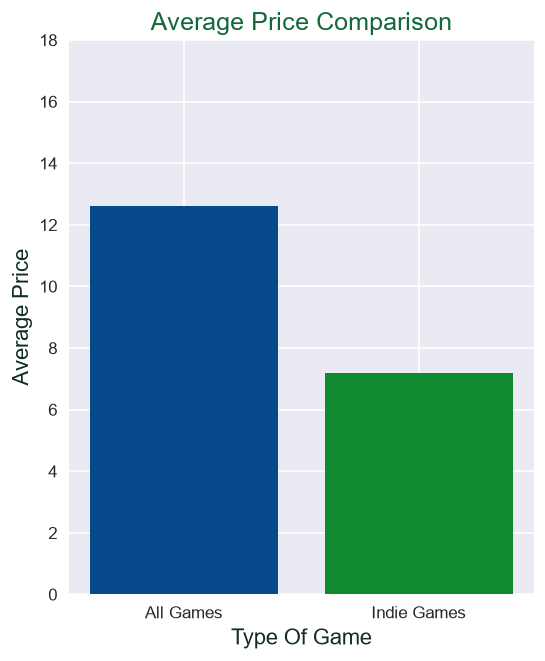

In [57]:
mask = new_df.Genres == 'Indie'
prices = [new_df.price.mean(),new_df[mask].price.mean()]
labels = ['All Games','Indie Games']

plt.figure(figsize=(5,6), dpi=120)

plt.bar(labels,prices,color=('#08488c','#118a2f'))
plt.title('Average Price Comparison',fontsize=15,color="#116838")
plt.xlabel('Type Of Game',fontsize=13,color='#112e1e')
plt.ylabel('Average Price',fontsize=13,color='#112e1e')
plt.ylim(0,18)
plt.show()

In [58]:
# on average the indie games are cheaper this makes sense because they are smaller games 
# made by a small group of people and most indie games are cheap beacuse they dont take a lot of time to make

#### Grouping by dates

In [59]:
new_df.insert(loc=2,column='Year',value=new_df.ReleaseDate.dt.year)
new_df.insert(loc=3,column='Month',value=new_df.ReleaseDate.dt.month_name())
new_df.insert(loc=4,column='Day',value=new_df.ReleaseDate.dt.day_name())

In [60]:
new_df.head()

,Appid,Name,Year,Month,Day,ReleaseDate,Genres,Developers,Publishers,price,Tags,ReviewScore,PositiveReview,NegativeReview
0,3764200,Resident Evil Requiem,2026,February,Thursday,2026-02-26,"Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",69.99,"Action,Adventure",9,23715,793
1,730,Counter-Strike 2,2012,August,Tuesday,2012-08-21,"Action,Free To Play",Valve,Valve,0.00,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393
2,1808500,ARC Raiders,2025,October,Thursday,2025-10-30,Action,Embark Studios,Embark Studios,39.99,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194
3,359550,Tom Clancy's Rainbow Six Siege,2015,December,Tuesday,2015-12-01,"Action,Free To Play",Ubisoft Montreal,Ubisoft,0.00,"Action,Free To Play",8,522886,106839
4,1172470,Apex Legends™,2020,November,Wednesday,2020-11-04,"Action,Adventure,Free To Play",Respawn,Electronic Arts,0.00,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216


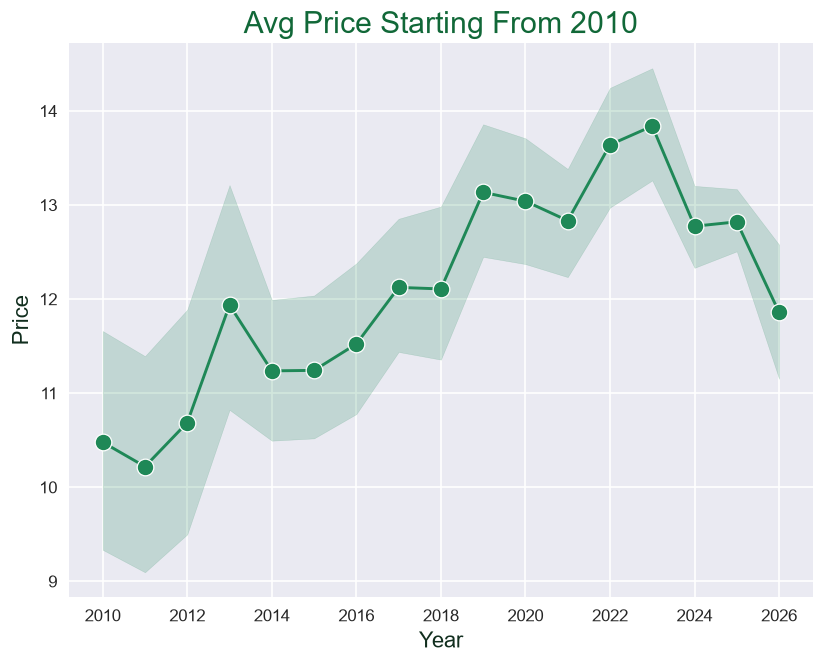

In [61]:
# has the prices of games gone up?
mask = new_df.Year >= 2010

plt.figure(figsize=(8,6),dpi=120)

sb.lineplot(data=new_df[mask],x=new_df.Year[mask],y=new_df.price[mask],marker='o',markersize=10,color="#1F8857")
plt.title('Avg Price Starting From 2010',fontsize=18,color="#116838")
plt.ylabel('Price',fontsize=13,color='#112e1e')
plt.xlabel('Year',fontsize=13,color='#112e1e')
plt.show()

In [62]:
# yes they have sometimes they go back down but they do go back up eventually
# however with the rize of indie games (cheap games) it might slowly go down

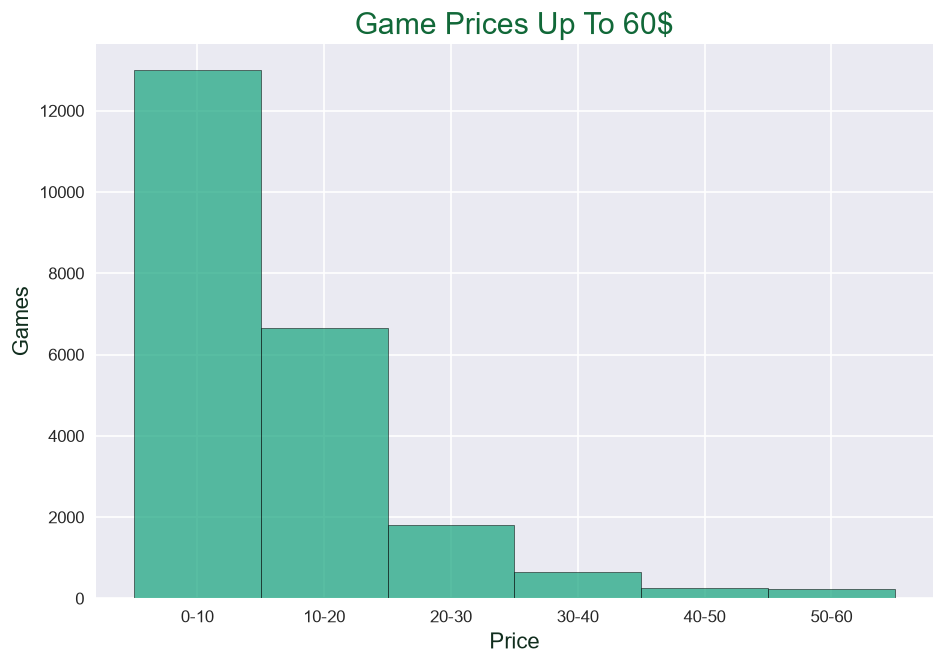

In [63]:
# how do the Steam game prices distribute?
max_60 = new_df.price <=60

plt.figure(figsize=(9,6),dpi=120)

sb.histplot(data=new_df[max_60],x='price',bins=[0, 10, 20, 30, 40, 50, 60],color='#22a884')
plt.title('Game Prices Up To 60$',fontsize=18,color="#116838")
plt.xlabel('Price',fontsize=13,color='#112e1e')
plt.xticks([5,15,25,35,45,55],['0-10','10-20','20-30','30-40','40-50','50-60'])
plt.ylabel('Games',fontsize=13,color='#112e1e')
plt.show()

In [64]:
# looks like most games cost up to 20$ and thats without any fillters too

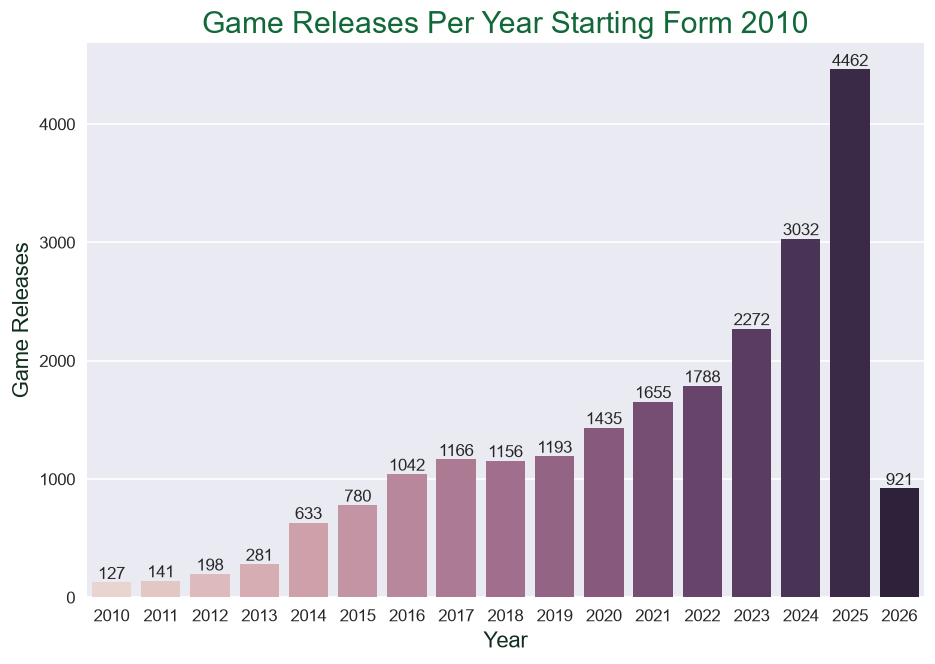

In [65]:
# have game releases increased with the years?
mask = new_df.Year >= 2010

plt.figure(figsize=(9,6),dpi=120)

ax = sb.countplot(new_df[mask],x='Year',hue='Year',legend=False)
plt.title('Game Releases Per Year Starting Form 2010',fontsize=18,color="#116838")
plt.xlabel('Year',fontsize=13,color='#112e1e')
plt.ylabel('Game Releases',fontsize=13,color='#112e1e')

for x in ax.containers:
    ax.bar_label(x)
    
plt.show()

In [66]:
# yes game releases have been going up (2026 doesn't have the data for the full year)

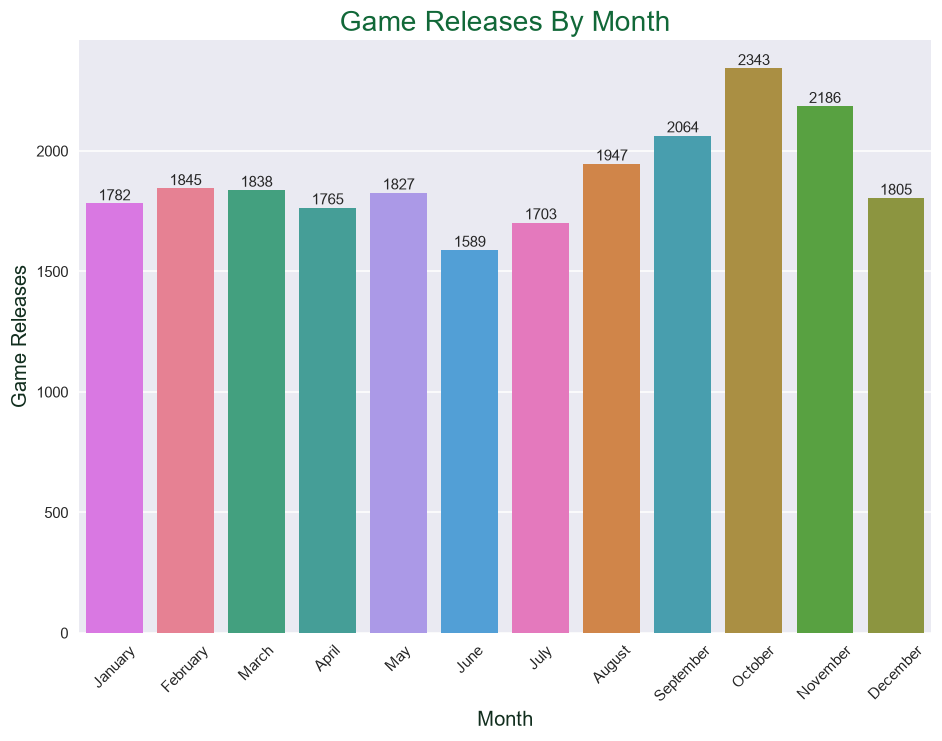

In [67]:
# is there a specific month that developers release more games in?
plt.figure(figsize=(10,7),dpi=110)
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']

ax = sb.countplot(data= new_df,x= 'Month',hue= 'Month',order=month_order,legend=False)
plt.title('Game Releases By Month',fontsize=18,color="#116838")
plt.xlabel('Month',fontsize=13,color='#112e1e')
plt.ylabel('Game Releases',fontsize=13,color='#112e1e')
plt.xticks(rotation=45)

for x in ax.containers:
    ax.bar_label(x)
plt.show()

In [68]:
# yes October is the month that most games get releases at because of sales
# like the Steam winter sale and christmas (they release them on October so that you can plan for a christmass present)

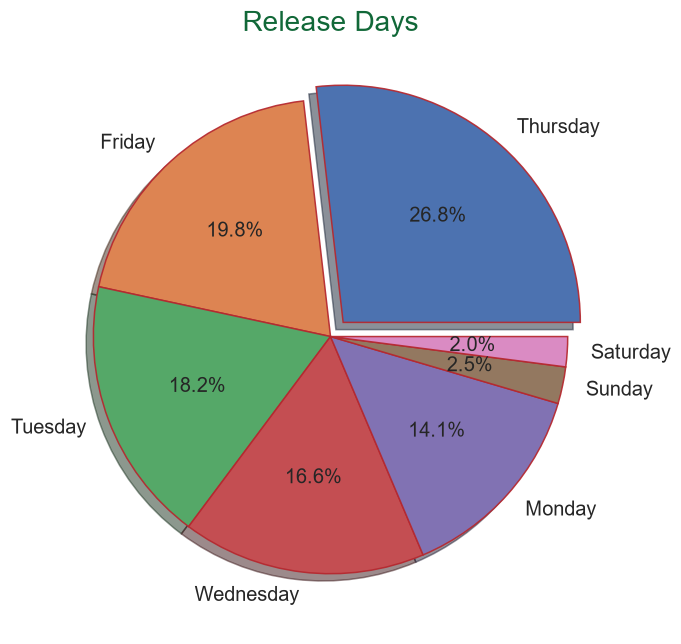

In [69]:
# what about the day the game gets released?
count_days = new_df.Day.value_counts()
colors = sb.color_palette('deep',7)

plt.figure(figsize=(10,7),dpi=110)

plt.pie(count_days,labels=count_days.index,autopct='%1.1f%%',explode=[0.08,0,0,0,0,0,0],colors=colors,
        textprops={'fontsize': 13,},shadow=True,wedgeprops={'edgecolor':'#b5282fed','linewidth':1})
plt.title('Release Days',fontsize=18,color="#116838")
plt.show()

In [70]:
# Thursday is the most popular day to release games this makes sense because they get released right before the weekend

# In Conclusion 💡

We learnt all the things i wanted to know about and more.

Things like:

The increase in prices, but that they might start to go down because more and more indie devs

are starting to release games.

That more and more games get released every year.

When most games get released and why.

And more.

# Recommendations 🧾

I recommend publishing games in the first half of the year especially if you are a new dev

because it will make your game stand out more and you will not be releasing your game together with all the big devs.

Also you should release your game on thursday i know it will make you stand out less, but people mostly play games on the weekend

so i think it will be better.

If you want to make a game that will stand out, avoid making an Action/Adventure game becasue there are already alot of them.